<a href="https://colab.research.google.com/github/jsmak/mytransformer/blob/main/notebooks/05_Multihead_attention_step2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 트랜스포머의 어텐션 메커니즘 (Attention is All you Need, Figure 2) 설명

이 노트북은 ["Attention Is All You Need"](https://arxiv.org/abs/1706.03762) 논문의 핵심 메커니즘인 "Scaled Dot-Product Attention"과   
"Multi-Head Attention"을 PyTorch로 구현하고 그 동작을 시각적으로 설명합니다.  

### 1. Scaled Dot-Product Attention (`ScaledDotProductAttention` 클래스)

논문의 Figure 2(왼쪽)에 해당하는 부분입니다.   
입력으로 Query (Q), Key (K), Value (V)를 받아서 어텐션 스코어를 계산하고, 스케일링 후 소프트맥스를 적용하여 어텐션 가중치를 얻습니다.   
이 가중치를 Value에 곱하여 최종적인 컨텍스트 벡터를 생성합니다.  

- **MatMul (Q와 K 트랜스포즈의 곱)**: 쿼리가 키와 얼마나 관련이 있는지를 측정합니다.  
- **Scale (루트 d_k로 나누기)**: 내적 값이 너무 커져 소프트맥스 함수의 기울기가 작아지는 것을 방지합니다.  
- **SoftMax**: 각 Value에 대한 확률 분포를 만들어 줍니다.  
- **MatMul (어텐션 가중치와 V의 곱)**: 이 확률 분포를 바탕으로 Value들을 가중 평균하여 최종 출력(컨텍스트 벡터)을 만듭니다.  
- **(Optional) Mask**: 특정 토큰(예: 패딩 토큰, 미래 토큰)이 어텐션에 영향을 주지 않도록 마스킹합니다.  

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# 논문 Figure 2 (왼쪽) - Scaled Dot-Product Attention
# Attention(Q,K,V) = softmax(QK^T / √d_k) V
# ============================================================
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head):
        super().__init__()
        self.d_head = d_head

    def forward(self, Q, K, V, attn_mask=None):
        # MatMul: Q @ K^T
        attention_scores = Q @ K.transpose(-2, -1)

        # (Optional) Mask: 미래 토큰을 가리기 위한 마스크
        if attn_mask is not None:
            attention_scores = attention_scores.masked_fill(attn_mask == 0, float("-inf"))

        # Scale + SoftMax
        attention_weights = F.softmax(attention_scores / math.sqrt(self.d_head), dim=-1)

        # MatMul: attention_weights @ V
        context_vector = attention_weights @ V
        return context_vector


### 2. Multi-Head Attention (`MultiHeadAttention` 클래스)

논문의 Figure 2(오른쪽)에 해당하는 부분입니다. 'Attention' 메커니즘을 여러 번 병렬적으로 수행하여 다양한 관점에서 정보를 포착할 수 있도록 합니다.   
각 "헤드"는 입력 Q, K, V에 대해 독립적인 선형 변환(`W_q`, `W_k`, `W_v`)을 적용한 후 `ScaledDotProductAttention`을 수행합니다.   
이렇게 얻은 여러 헤드의 출력을 `Concat` (연결)한 다음, 최종적으로 하나의 선형 변환(`W_o`)을 거쳐 출력됩니다.  
$$MultiHead(Q,K,V) = Concat(head_1, ..., head_h) W_O$$

$$where\ head_i = Attention(Q W_{q_i}, K W_{k_i}, V W_{v_i})$$

- **Linear (각 헤드별)**: Q, K, V를 여러 개의 작은 차원(`d_head`)으로 투영합니다. 이를 통해 모델이 다양한 표현 공간에서 어텐션을 학습할 수 있습니다.
- **h개의 Scaled Dot-Product Attention 병렬 수행**: 각 헤드에서 독립적으로 어텐션을 계산합니다.
- **Concat**: 각 헤드의 결과를 하나로 연결하여 원래 `d_model` 차원으로 복원합니다.
- **Linear (최종 출력)**: 연결된 결과를 다시 한 번 선형 변환하여 최종 출력을 생성합니다.

이러한 멀티 헤드 어텐션은 모델이 문장 내의 서로 다른 위치에서 정보를 공동으로 집중할 수 있도록 하여, 문맥 정보를 더 풍부하게 이해하게 합니다.

In [2]:
# ============================================================
# 논문 Figure 2 (오른쪽) - Multi-Head Attention
# ============================================================
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads  # d_k = d_v = d_model / h

        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.out = nn.Linear(d_model, d_model, bias=False)
        self.attention = ScaledDotProductAttention(self.d_head)

    def forward(self, xq, xk, xv, attn_mask=None):
        batch_size = xq.size(0)
        Q = self.W_q(xq).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        K = self.W_k(xk).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        V = self.W_v(xv).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)

        # Apply Scaled Dot Product Attention
        x = self.attention(Q, K, V, attn_mask)

        # Concatenate and apply final linear
        head_output = x.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        out = self.out(head_output)
        return out

## 샘플 실행 결과 설명

`MultiHeadAttention` 모듈은 `d_model=9`, `num_heads=3`으로 설정되었습니다. 이는 각 어텐션 헤드가 `d_model / num_heads = 9 / 3 = 3` 차원의 Query, Key, Value를 처리함을 의미합니다.

**입력 `x`:**
- `x`의 형태는 `(batch_size, seq_len, d_model)`인 `(1, 4, 9)`입니다. 이는 1개의 배치에 4개의 토큰(단어)이 있고, 각 토큰은 9차원의 벡터로 표현됨을 의미합니다.

**`MultiHeadAttention` 실행 과정:**

1.  **Q, K, V에 대한 선형 변환:**
    - 입력 `x` (`(1, 4, 9)`)는 `mha.W_q`, `mha.W_k`, `mha.W_v`라는 독립적인 선형 레이어를 통과합니다. 각 레이어의 가중치 행렬은 `(d_model, d_model)` 형태인 `(9, 9)`입니다.
    - 이 선형 변환의 결과(예: `mha.W_q(x)`)는 `(batch_size, seq_len, d_model)` 형태인 `(1, 4, 9)`를 가집니다.

2.  **멀티 헤드 어텐션을 위한 재구성:**
    - 변환된 `Q`, `K`, `V` 텐서들은 `(batch_size, seq_len, num_heads, d_head)` 형태(`(1, 4, 3, 3)`)로 재구성된 후 `(batch_size, num_heads, seq_len, d_head)` 형태(`(1, 3, 4, 3)`)로 전치(transpose)됩니다. 이는 `num_heads` 개의 헤드가 병렬로 처리할 수 있도록 각 헤드에 맞는 `seq_len` 길이의 `d_head` 차원 쿼리, 키, 값을 준비하는 과정입니다.

3.  **Scaled Dot-Product Attention 수행:**
    - 재구성된 `Q`, `K`, `V` 텐서(`(1, 3, 4, 3)`)는 `MultiHeadAttention` 내부에 있는 **단일** `ScaledDotProductAttention` 인스턴스(`mha.attention`)에 전달됩니다. 이 인스턴스는 모든 헤드에 대한 어텐션 스코어와 가중치를 동시에 계산합니다.
    - 이 단계의 출력(`attn_output_all_heads`)은 `(batch_size, num_heads, seq_len, d_head)` 형태인 `(1, 3, 4, 3)`을 가집니다. 여기서 `attn_output_all_heads[0, i, :, :]`는 `Head i`의 개별 출력을 `(seq_len, d_head)` 형태(`(4, 3)`)로 나타냅니다.

4.  **`Concat` (연결):**
    - `attn_output_all_heads` (`(1, 3, 4, 3)`)는 다시 `(batch_size, seq_len, num_heads, d_head)` 형태(`(1, 4, 3, 3)`)로 전치된 후, `num_heads`와 `d_head` 차원이 하나의 `d_model` 차원으로 이어 붙여집니다.
    - 이 연결 결과(`context` 텐서)의 형태는 `(batch_size, seq_len, d_model)`인 `(1, 4, 9)`가 되며, 이는 원래 `d_model` 차원으로 복원된 것입니다.

5.  **최종 선형 변환:**
    - 연결된 결과 텐서(`(1, 4, 9)`)는 최종 선형 레이어 `mha.out`을 통과합니다. 이 레이어의 가중치 행렬은 `(d_model, d_model)` 형태인 `(9, 9)`입니다.
    - 최종 출력 `output`은 입력 `x`와 동일한 `(batch_size, seq_len, d_model)` 형태인 `(1, 4, 9)`를 가집니다.

이러한 과정을 통해 `MultiHeadAttention`은 입력 시퀀스의 각 토큰에 대해 여러 개의 어텐션 헤드를 통해 다양한 관계 정보를 추출하고, 이를 통합하여 최종 출력을 생성함을 확인할 수 있습니다.

In [4]:
#============================================================
# 샘플 실행
# ============================================================
d_model = 9
num_heads = 3
d_head = d_model // num_heads  # 3

# 4개 토큰으로 구성된 문장 1개 (batch=1)
seq_len = 4
batch_size = 1

# 입력: (batch, seq_len, d_model) = (1, 4, 9)
x = torch.randn(batch_size, seq_len, d_model)

print("=" * 50)
print("설정값")
print(f"  d_model    = {d_model}")
print(f"  num_heads  = {num_heads}")
print(f"  d_head     = {d_head} (= d_model / num_heads)")
print(f"  seq_len    = {seq_len}")
print(f"  batch_size = {batch_size}")
print("=" * 50)

print(f"\n입력 x shape: {x.shape}")
print(f"입력 x:\n{x}")

# Multi-Head Attention 생성 및 실행
# Self-Attention이므로 xq = xk = xv = x
mha = MultiHeadAttention(d_model, num_heads)
output = mha(xq=x, xk=x, xv=x)

print(f"\n출력 shape: {output.shape}")
print(f"출력:\n{output}")

# 각 head의 중간 과정 확인
print("\n" + "=" * 50)
print("각 head별 중간 과정")
print("=" * 50)

# W_q, W_k, W_v를 x에 적용
Q_proj = mha.W_q(x)
K_proj = mha.W_k(x)
V_proj = mha.W_v(x)

# 각 헤드별 Q, K, V로 재구성 및 전치
Q_reshaped = Q_proj.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2)
K_reshaped = K_proj.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2)
V_reshaped = V_proj.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2)

# Scaled Dot Product Attention의 전체 헤드 출력
attn_output_all_heads = mha.attention(Q_reshaped, K_reshaped, V_reshaped)

for i in range(num_heads):
    Q_i = Q_reshaped[:, i, :, :]
    K_i = K_reshaped[:, i, :, :]
    V_i = V_reshaped[:, i, :, :]
    head_output_i = attn_output_all_heads[:, i, :, :]

    print(f"\n--- Head {i} ---")
    print(f"  Q[{i}] shape:     {Q_i.shape}  (batch, seq_len, d_head) = ({batch_size}, {seq_len}, {d_head})")
    print(f"  K[{i}] shape:     {K_i.shape}")
    print(f"  V[{i}] shape:     {V_i.shape}")
    print(f"  head_output[{i}] shape: {head_output_i.shape}")

# Concat 결과 확인 (최종 Linear 통과 전)
concatenated_output_for_display = attn_output_all_heads.transpose(1, 2).contiguous().view(batch_size, seq_len, d_model)

print(f"\nConcat 후 shape: {concatenated_output_for_display.shape}")
# Linear layer의 weight는 mha.out.weight로 접근
print(f"W_o shape:       {mha.out.weight.shape}  (d_model, d_model) = ({d_model}, {d_model})")
print(f"최종 출력 shape: {output.shape}  (batch, seq_len, d_model)")

설정값
  d_model    = 9
  num_heads  = 3
  d_head     = 3 (= d_model / num_heads)
  seq_len    = 4
  batch_size = 1

입력 x shape: torch.Size([1, 4, 9])
입력 x:
tensor([[[-0.5513,  0.7918,  0.6836, -0.1293,  1.3796,  2.3090, -0.9626,
           0.2730, -0.7131],
         [-1.0974,  0.7177, -0.1052, -0.5129, -1.3231, -0.9116, -0.5037,
           1.2073, -2.2403],
         [ 0.9934,  0.2159,  0.7146,  1.3971,  1.6938,  1.1536,  0.2964,
          -0.4943, -0.0151],
         [-0.4465,  2.5096, -0.5799,  1.0840,  0.3752, -0.5297,  0.3585,
           0.7439,  2.0259]]])

출력 shape: torch.Size([1, 4, 9])
출력:
tensor([[[ 0.1322,  0.0379,  0.0899, -0.2580,  0.0286,  0.2514, -0.0129,
          -0.2687,  0.0917],
         [ 0.1353,  0.0464,  0.1157, -0.1708, -0.1195,  0.2371, -0.0910,
          -0.1786, -0.0086],
         [ 0.0749, -0.0298,  0.0858, -0.2808,  0.0234,  0.3017,  0.0160,
          -0.2114,  0.0009],
         [ 0.0734,  0.0622,  0.2000, -0.0972, -0.1713,  0.3230, -0.0573,
          -0.0974, -

## 입력 및 출력 텐서 시각화

`MultiHeadAttention` 모듈을 통과하기 전후의 텐서 `x`와 `output`의 값을 시각화하여 변화를 살펴봅니다. 각 행은 시퀀스 내의 한 토큰을 나타내고, 각 열은 해당 토큰의 `d_model` 차원 벡터의 한 요소를 나타냅니다. 히트맵을 통해 값의 분포와 변화를 직관적으로 파악할 수 있습니다.

## 각 Attention Head 출력 및 Concat 결과 시각화

`MultiHeadAttention` 내부에서 각 개별 헤드(H0, H1, H2)가 생성하는 출력과, 이들을 하나로 이어 붙인(`Concat`) `context` 텐서의 값을 시각화합니다. 이를 통해 각 헤드가 어떤 정보를 포착하고 있으며, 이 정보들이 어떻게 결합되는지 상세하게 이해할 수 있습니다.

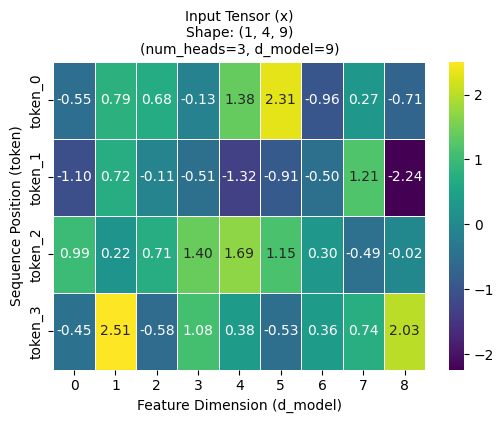

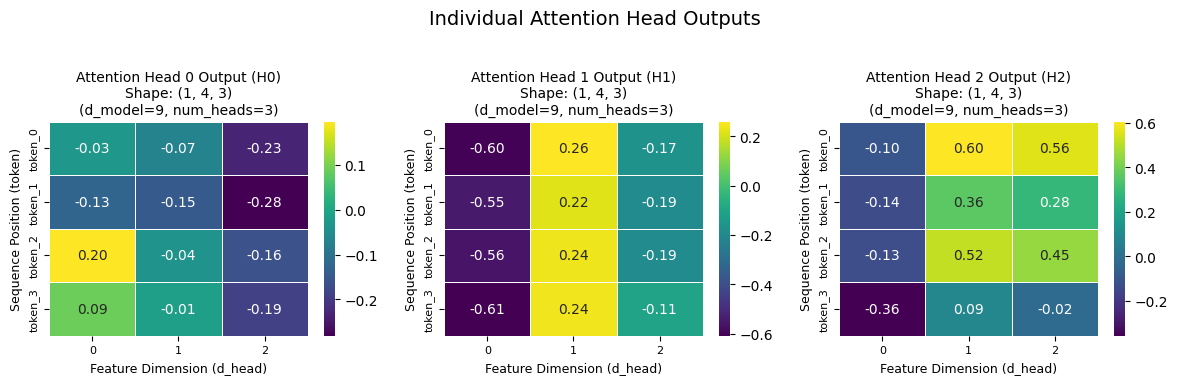

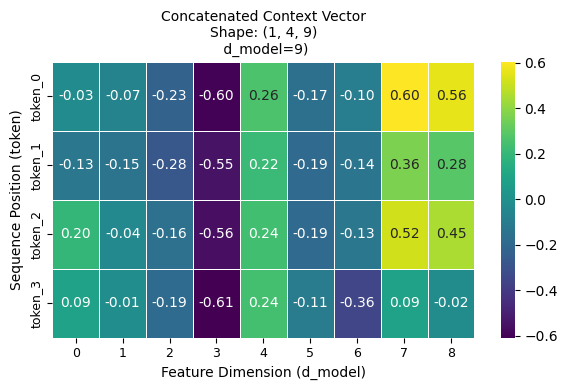

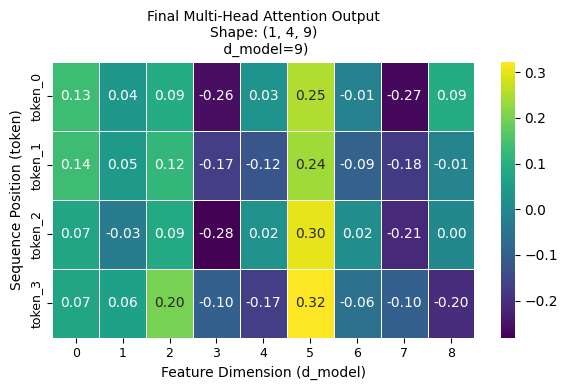

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Re-run the forward pass to capture intermediate head_outputs and context
# First, get the projected Q, K, V for all heads
Q_proj_all = mha.W_q(x)
K_proj_all = mha.W_k(x)
V_proj_all = mha.W_v(x)

# Reshape and transpose to get multi-head Q, K, V
Q_all_heads_shaped = Q_proj_all.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2) # (batch_size, num_heads, seq_len, d_head)
K_all_heads_shaped = K_proj_all.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2) # (batch_size, num_heads, seq_len, d_head)
V_all_heads_shaped = V_proj_all.view(batch_size, seq_len, num_heads, d_head).transpose(1, 2) # (batch_size, num_heads, seq_len, d_head)

# Apply Scaled Dot Product Attention to all heads in parallel
attn_output_all_heads = mha.attention(Q_all_heads_shaped, K_all_heads_shaped, V_all_heads_shaped) # (batch_size, num_heads, seq_len, d_head)

head_outputs_captured = []
for i in range(num_heads):
    # Extract output for each individual head
    head_output_i = attn_output_all_heads[:, i, :, :] # (batch_size, seq_len, d_head)
    head_outputs_captured.append(head_output_i)

# Concatenate the outputs from each head along the last dimension
context_captured = torch.cat(head_outputs_captured, dim=-1) # (batch_size, seq_len, d_model)

# Recalculate final output for consistency, assuming mha, x are available
output_final = mha(xq=x, xk=x, xv=x)


# Example text labels for sequence positions
# You can customize these based on your actual data/context
seq_labels = [f'token_{i}' for i in range(seq_len)] # Using generic labels as actual words are not known

# Input Tensor (x) Visualization
plt.figure(figsize=(6, 4))
sns.heatmap(x.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Input Tensor (x)\nShape: ({batch_size}, {seq_len}, {d_model})\n(num_heads={num_heads}, d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)')
plt.ylabel('Sequence Position (token)')
plt.show()


# -------------------------------------------------------------
# Visualize each head output (H0, H1, H2) horizontally
# -------------------------------------------------------------
plt.figure(figsize=(12, 4)) # Adjusted for horizontal layout of 3 plots

for i, head_output in enumerate(head_outputs_captured):
    plt.subplot(1, mha.num_heads, i + 1) # 1 row, num_heads columns
    sns.heatmap(head_output.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
    plt.title(f'Attention Head {i} Output (H{i})\nShape: ({batch_size}, {seq_len}, {d_head})\n(d_model={d_model}, num_heads={num_heads})', fontsize=10)
    plt.xlabel('Feature Dimension (d_head)', fontsize=9)
    plt.ylabel('Sequence Position (token)', fontsize=9)
    # Adjusting tick label font size
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)

plt.suptitle('Individual Attention Head Outputs', fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

# -------------------------------------------------------------
# Visualize the concatenated context
# -------------------------------------------------------------
plt.figure(figsize=(6, 4)) # A bit larger for d_model
sns.heatmap(context_captured.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Concatenated Context Vector\nShape: ({batch_size}, {seq_len}, {d_model})\n d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)', fontsize=10)
plt.ylabel('Sequence Position (token)', fontsize=10)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Visualize the final Multi-Head Attention output
# -------------------------------------------------------------
plt.figure(figsize=(6, 4)) # Same size as context for comparison
sns.heatmap(output_final.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Final Multi-Head Attention Output\nShape: ({batch_size}, {seq_len}, {d_model})\n d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)', fontsize=10)
plt.ylabel('Sequence Position (token)', fontsize=10)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()